In [1]:
import functools
import os

from ultralytics import YOLO
import pandas as pd

import ultralytics_validator_wrapper
from tflite_inference import TFLiteInferer
from tflite_inference_input_adapter import TFLiteInferenceWithInputAdapter

pd.options.display.float_format = '{:.3f}'.format

%matplotlib inline
%load_ext autoreload
%autoreload 2

TensorFlow version:  2.17.0


In [3]:
BASE_WEIGHTS_PTH = "results/filtered_v3_margin_15_reduced_quality_yolov8n"

BASE_PTH = "/home/klymy/data/people_detection/filtered_v3_margin_15"

VAL_PTH = os.path.join(BASE_PTH, "project.yaml")
HOLDOUT_PTH = os.path.join(BASE_PTH, "project_holdout.yaml")
ALGOTEST_PTH = os.path.join(BASE_PTH, "project_algotest.yaml")

PG2 = "quality_reduce_comparison/cam4_poc_15/project_pg.yaml"
PG2_PROCESSED = "quality_reduce_comparison/cam4_poc_15_nn/project_pg.yaml"

# CONF_TH = 0.25
# IOU_TH = 0.55
# CONF_TH = 0.35
# IOU_TH = 0.5
# CONF_TH = 0.25
# IOU_TH = 0.5
CONF_TH = 0.3
IOU_TH = 0.5

args = dict(
    data=HOLDOUT_PTH,
    task="pose",
    device=[0],
    batch=128,
    verbose=False,
    conf=CONF_TH,
    iou=IOU_TH,
    imgsz=320,
    model="val",
    rect=False,
    single_cls=False,
)

In [4]:
model = YOLO(os.path.join(BASE_WEIGHTS_PTH, "weights/best.pt"))

In [5]:
inferer = TFLiteInferer(
    yolo_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/best_saved_model/best_full_integer_quant.tflite"),
    head_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/head_saved_model/head_float32.tflite"),
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/holdout.cache... 22049 images, 556 backgrounds, 0 corrupt: 100%|██████████| 22049/22049 [00:00<?, ?it/s]
tst validation: 100%|██████████| 173/173 [14:26<00:00,  5.01s/it]


                   all      22049     114004      0.869      0.842      0.886      0.577      0.897      0.869      0.917      0.912
   task    F1     P     R  MAP@50
0   box 0.855 0.869 0.842   0.886
1  pose 0.883 0.897 0.869   0.917


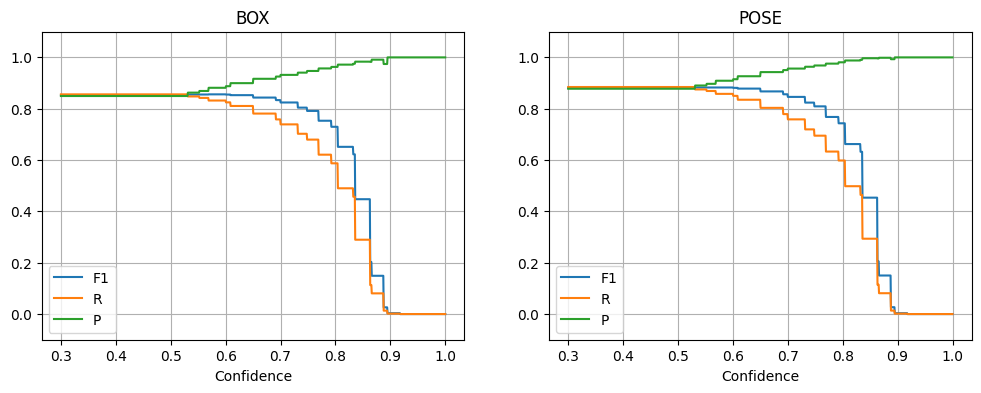

In [6]:
ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    True
)

In [7]:
args["data"] = ALGOTEST_PTH

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/data/people_detection/filtered_v3_margin_15/labels/algotest.cache... 9572 images, 559 backgrounds, 0 corrupt: 100%|██████████| 9572/9572 [00:00<?, ?it/s]
tst validation:   0%|          | 0/75 [00:00<?, ?it/s]

tst validation: 100%|██████████| 75/75 [06:16<00:00,  5.02s/it]


                   all       9572      51930      0.867      0.819      0.882      0.555       0.88      0.851      0.907      0.901
   task    F1     P     R  MAP@50
0   box 0.842 0.867 0.819   0.882
1  pose 0.865 0.880 0.851   0.907


In [8]:
args["data"] = PG2

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:08<00:00,  4.01s/it]


                   all        191        417      0.633      0.496       0.58      0.399      0.673      0.528      0.604      0.601
   task    F1     P     R  MAP@50
0   box 0.556 0.633 0.496   0.580
1  pose 0.591 0.673 0.528   0.604


In [9]:
args["data"] = PG2_PROCESSED

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15_nn/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:07<00:00,  3.93s/it]


                   all        191        417       0.79      0.694      0.783      0.565      0.783      0.736      0.804      0.799
   task    F1     P     R  MAP@50
0   box 0.739 0.790 0.694   0.783
1  pose 0.759 0.783 0.736   0.804


In [10]:
inferer_adapter = TFLiteInferenceWithInputAdapter(
    yolo_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/best_saved_model/best_full_integer_quant.tflite"),
    head_pth=os.path.join(BASE_WEIGHTS_PTH, "weights/head_saved_model/head_float32.tflite"),
    adapter_pth="input_adapter/input_adapter_full_integer_quant.tflite",
    conf_th=CONF_TH,
    iou_th=IOU_TH,
    imgsz=320,
)

In [11]:
args["data"] = PG2

ultralytics_validator_wrapper.validate_model(
    args,
    model,
    functools.partial(ultralytics_validator_wrapper.predict_tflite, inferer_adapter, args),
    False,
)

val: Scanning /home/klymy/projects/researches/people_detection_pg2/quality_reduce_comparison/cam4_poc_15/labels/val.cache... 191 images, 5 backgrounds, 0 corrupt: 100%|██████████| 191/191 [00:00<?, ?it/s]


tst validation: 100%|██████████| 2/2 [00:08<00:00,  4.46s/it]


                   all        191        417      0.925      0.804      0.893      0.653      0.942      0.819      0.907      0.905
   task    F1     P     R  MAP@50
0   box 0.861 0.925 0.804   0.893
1  pose 0.876 0.942 0.819   0.907
